# FineWeb2 Language Selection via Lang2Vec Genetic Distance Metrics

### Common Setup

In [1]:
# Setting system path and project root
import os
import sys

PROJECT_ROOT_DIR = os.path.abspath('../../')
sys.path.append(PROJECT_ROOT_DIR) # bringing system path to project root

def get_fp(relative_path):
    return os.path.join(PROJECT_ROOT_DIR, relative_path)

### Reading Language List with Resource Category Data

In [2]:
import pandas as pd

csv_path = get_fp("data_dir/fineweb2_metadata/fw2_metadata_with_resource_category.csv")
fw2_lang_doc_distr_df = pd.read_csv(csv_path)

# document count filter (> 1k documents)
DOC_COUNT_COL = "documents"   # ← rename if the column has a different name
MIN_DOCS = 1_000
# Remove rows where the "subset" column ends with "_removed"
mask = (
    ~fw2_lang_doc_distr_df["subset"].astype(str).str.endswith("_removed") &
    (fw2_lang_doc_distr_df["split"] == "train") &
    (fw2_lang_doc_distr_df["family"] != "-")
)

mask = mask & (fw2_lang_doc_distr_df[DOC_COUNT_COL] >= MIN_DOCS)

fw2_lang_doc_distr_df = fw2_lang_doc_distr_df.loc[mask].reset_index(drop=True)

print(f'Shape of fw2 dataframe after filtering values: {fw2_lang_doc_distr_df.shape}')

columns_of_interest = ["subset", "code", "name", "script", "family"]

for col in columns_of_interest:
    if col in fw2_lang_doc_distr_df.columns:
        uniques = fw2_lang_doc_distr_df[col].dropna().unique()   # drop NaN, then get uniques
        print(f"\nUnique values in '{col}' ({len(uniques)} total):")
        # print(uniques)
    else:
        print(f"\nColumn '{col}' not found in the CSV.")

Shape of fw2 dataframe after filtering values: (474, 15)

Unique values in 'subset' (474 total):

Unique values in 'code' (449 total):

Unique values in 'name' (449 total):

Unique values in 'script' (32 total):

Unique values in 'family' (43 total):


### Read Lang2Vec Distance Matrix

In [3]:
# Load lang2vec genetic distance
from lang2vec import lang2vec as l2v
l2v.genetic_distance('frr','dan')

/cluster/user/repos/moe-study/src/virt-envs/data_sample_venv/lib/python3.12/site-packages/lang2vec/lang2vec.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


np.float64(0.625)

In [4]:
# Lang2Vec provides a collection of supported language identifiers
available_langs = set(l2v.DISTANCE_LANGUAGES)          # e.g. {'eng', 'fra', ...}

# Ensure codes are strings for reliable comparison
codes_series = fw2_lang_doc_distr_df['code'].astype(str)

# Boolean mask: True where the code exists in Lang2Vec
matches_mask = codes_series.isin(available_langs)

# Counts
num_matches    = matches_mask.sum()
num_no_matches = (~matches_mask).sum()
print(f"Number of codes present in Lang2Vec: {num_matches}")
print(f"Number of codes NOT present in Lang2Vec: {num_no_matches}")

# Detailed list of missing codes + their language names
missing_df = fw2_lang_doc_distr_df.loc[~matches_mask, ['code', 'name']]
print("\nCodes not found in Lang2Vec:")
print(missing_df.to_string(index=False))

Number of codes present in Lang2Vec: 470
Number of codes NOT present in Lang2Vec: 4

Codes not found in Lang2Vec:
code              name
 hyw  Western Armenian
 nah Nahuatl languages
 tok         Toki Pona
 szy          Sakizaya


In [5]:
# from lang2vec.lang2vec import *
# frr_ind = DISTANCE_LANGUAGES.index('frr')
# dan_ind = DISTANCE_LANGUAGES.index('dan')
# with zf(DISTANCES_FILE, 'r') as zp:
#     data = sparse.load_npz(zp.open(map_distance_to_filename('genetic')))
#     print(data[frr_ind,dan_ind])

### Language Selection and Visualization

In [6]:

# Imports & helper utilities
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.manifold import MDS
import warnings
import numpy as np         # ensure NumPy is available for jitter
import umap
from lang2vec.lang2vec import *

2026-02-21 11:56:12.825001: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-21 11:56:12.855537: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-02-21 11:56:13.612791: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [7]:
# Build / expose the full distance matrix
def get_distance_matrix():
    """
    Load the Lang2Vec genetic distance matrix and return:
        - `dist_matrix`: dense (M x M) array where M = number of Lang2Vec‑available languages
        - `present_codes`: array of the language codes that correspond to rows/cols
    """
    # Load the sparse matrix that stores all pair‑wise genetic distances
    with zf(DISTANCES_FILE, 'r') as zp:
        data = sparse.load_npz(zp.open(map_distance_to_filename('genetic')))

    # `DISTANCE_LANGUAGES` gives the ordering of language codes in the matrix
    lang_to_idx = {code: i for i, code in enumerate(DISTANCE_LANGUAGES)}

    # Languages that have a genetic distance entry (already filtered above)
    present_codes = codes_series[matches_mask].astype(str).unique()
    present_idxs = np.array([lang_to_idx[code] for code in present_codes])

    # # Slice & densify
    # dist_mat = data[present_idxs[:, None], present_idxs].toarray()

    # # Symmetrise & clean diagonal
    # dist_mat = (dist_mat + dist_mat.T) / 2.0
    # np.fill_diagonal(dist_mat, 0.0)
    
    # The matrix is upper sparse, we should make sure not to choose d[i,j] where i > j because it will return 0 (look into lang2vec.py#402)
    dist_mat = [[data[lang2_idx, lang1_idx] if lang1_idx > lang2_idx else data[lang1_idx, lang2_idx]  for lang2_idx in present_idxs] for lang1_idx in present_idxs]
    dist_mat = np.asarray(dist_mat, dtype=np.float64)
    return dist_mat, present_codes

In [8]:

# Greedy farthest‑point selection (max‑min greedy)
def select_top_n_diverse(n: int, seed: int | None = None) -> list[str]:
    """
    Select `n` language codes that are as far apart from each other as possible.
    """
    if n <= 0:
        return []

    # Load the pre‑computed distance matrix and the corresponding language codes
    dist_matrix, present_codes = get_distance_matrix()
    
    m = len(present_codes)

    if n > m:
        raise ValueError(f"Requested {n} languages but only {m} are available.")

    rng = np.random.default_rng(seed)

    # Initial point
    if seed is not None:
        # Random start (reproducible via the provided seed)
        first_idx = int(rng.integers(m))
    else:
        # Deterministic start: language with the largest average distance
        avg_dists = dist_matrix.mean(axis=1)
        first_idx = int(np.argmax(avg_dists))

    selected_idx = [first_idx]

    # Initialise d_min for all points (distance to the current set)
    # For every candidate j, d_min[j] = distance to the nearest selected point
    d_min = dist_matrix[:, first_idx].copy()          # shape (m,)

    # Ensure the already‑selected point has distance 0 (so it never gets re‑chosen)
    d_min[first_idx] = -np.inf
    
    # Greedy expansion until we have `n` points
    while len(selected_idx) < n:
        # Choose the candidate with the largest distance to its nearest neighbour in S
        next_idx = int(np.argmax(d_min))
        selected_idx.append(next_idx)

        # Update d_min for the remaining candidates:
        # new distance = min(old distance, distance to the newly added point)
        # (vectorised for speed)
        d_min = np.minimum(d_min, dist_matrix[:, next_idx])

        # Prevent re‑selection of the point we just added
        d_min[next_idx] = -np.inf

    # Return language codes in the order they were selected
    return [present_codes[i] for i in selected_idx]

In [9]:
# Visualisation helpers
def _plot_embedding(emb, title, selected_codes, all_codes):
    """Common scatter plot routine."""
    plt.figure(figsize=(6, 6))
    plt.scatter(emb[:, 0], emb[:, 1], s=30, c='lightgray', label='All languages')
    # Highlight selected
    sel_mask = np.isin(all_codes, selected_codes)
    plt.scatter(emb[sel_mask, 0], emb[sel_mask, 1],
                s=80, c='tab:red', edgecolor='k', label='Selected')
    for i, txt in enumerate(all_codes[sel_mask]):
        plt.annotate(txt, (emb[sel_mask, 0][i], emb[sel_mask, 1][i]),
                     fontsize=9, fontweight='bold')
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_umap(dist_matrix, codes, selected_codes):
    """2‑D UMAP of the distance vectors with warnings suppressed."""
    warnings.filterwarnings(
        "ignore",
        message="using precomputed metric; inverse_transform will be unavailable",
        category=UserWarning,
        module="umap.umap_"
    )
    warnings.filterwarnings(
        "ignore",
        message="Spectral initialisation failed!*",
        category=UserWarning,
        module="umap.spectral"
    )

    jitter = 1e-9 * np.random.rand(*dist_matrix.shape)
    dist_matrix_jittered = dist_matrix + jitter

    reducer = umap.UMAP(
        n_components=2,
        random_state=0,
        metric='precomputed',
        transform_seed=None,   # no inverse_transform ⇒ no warning
        n_jobs=1,              # explicit to avoid the "n_jobs overridden" warning
        init='spectral'        # keep spectral init; jitter makes it succeed
    )

    emb = reducer.fit_transform(dist_matrix_jittered)
    _plot_embedding(emb, "UMAP of Lang2Vec Genetic Distances", selected_codes, codes)

    warnings.filterwarnings("default", category=UserWarning)

def plot_pca(dist_matrix, codes, selected_codes):
    """2‑D PCA of the distance vectors."""
    pca = PCA(n_components=2, random_state=0)
    emb = pca.fit_transform(dist_matrix)
    _plot_embedding(emb, "PCA of Lang2Vec Genetic Distances", selected_codes, codes)

# def plot_umap(dist_matrix, codes, selected_codes):
#     """2‑D UMAP of the distance vectors."""
#     reducer = umap.UMAP(n_components=2, random_state=0, metric='precomputed')
#     # UMAP expects a *distance* matrix, so we pass it directly
#     emb = reducer.fit_transform(dist_matrix)
#     _plot_embedding(emb, "UMAP of Lang2Vec Genetic Distances", selected_codes, codes)

def plot_tsne(dist_matrix, codes, selected_codes):
    """2‑D t‑SNE of the distance vectors."""
    tsne = TSNE(n_components=2, metric='precomputed', random_state=0, init='random')
    emb = tsne.fit_transform(dist_matrix)
    _plot_embedding(emb, "t‑SNE of Lang2Vec Genetic Distances", selected_codes, codes)
    
def plot_mds(dist_matrix, codes, selected_codes):
    """2‑D classical MDS of the genetic distance matrix."""
    # `metric='precomputed'` tells MDS that we already have distances
    mds = MDS(n_components=2, metric=True, dissimilarity='precomputed',
              random_state=0, n_init=4, max_iter=300)
    emb = mds.fit_transform(dist_matrix)
    _plot_embedding(emb, "MDS of Lang2Vec Genetic Distances", selected_codes, codes)



In [10]:
# Run example & visualise (replace the final two lines of the notebook)
# Example: get the n most diverse languages
n = 200
top_n = select_top_n_diverse(n, seed=42)
print(f"Top‑{n} most diverse language codes:", top_n)

def print_selected_metadata(selected_codes):
    """
    Print df as a table for the given language codes.
    """
    # Filter the original dataframe; keep original column order
    sel_df = fw2_lang_doc_distr_df[fw2_lang_doc_distr_df["code"].astype(str).isin(selected_codes)]
    # Reset index for nicer display
    sel_df = sel_df.reset_index(drop=True)
    print("\n=== Metadata for selected languages ===")
    print(sel_df.to_string(index=False))
    return sel_df

sel_df = print_selected_metadata(top_n)

# Grab the matrix and the full list of present codes for visualisation
dist_mat, present_codes = get_distance_matrix()

Top‑200 most diverse language codes: ['azj', 'rus', 'cmn', 'jpn', 'ind', 'arb', 'vie', 'kor', 'fas', 'hun', 'nob', 'tha', 'ekk', 'lvs', 'tam', 'kat', 'khk', 'eus', 'nno', 'swh', 'epo', 'mww', 'kal', 'srd', 'che', 'ido', 'gug', 'ltg', 'vro', 'kbd', 'twi', 'cak', 'vol', 'abt', 'ayr', 'nhe', 'tlh', 'quy', 'dyu', 'luo', 'wal', 'sgs', 'aau', 'arn', 'ape', 'gym', 'tlf', 'maq', 'hmo', 'bvr', 'aak', 'khs', 'bjv', 'cav', 'cab', 'aom', 'doi', 'bsn', 'top', 'ile', 'wrk', 'bon', 'aby', 'cbs', 'fra', 'wol', 'brh', 'yre', 'som', 'hin', 'gle', 'dag', 'deu', 'ote', 'agd', 'ell', 'kha', 'med', 'mri', 'mya', 'bod', 'lus', 'new', 'kac', 'sag', 'tzm', 'ksw', 'acd', 'yor', 'fin', 'als', 'tel', 'hye', 'tgk', 'ava', 'cmo', 'mnw', 'sat', 'bru', 'ium', 'plt', 'tcy', 'yua', 'alt', 'bqc', 'amu', 'lat', 'khm', 'nrm', 'chv', 'hil', 'tet', 'tzo', 'brx', 'pag', 'abk', 'mjw', 'hus', 'guw', 'cop', 'sid', 'kbp', 'zyb', 'ben', 'npi', 'kan', 'pbt', 'amh', 'bbc', 'efi', 'aeu', 'tpz', 'tiv', 'yue', 'tly', 'qug', 'mbb', 'sw

In [11]:
# Evaluable languages – compute coverage for Belebele and FLORES separately
from data_prep.loss_analysis_tokenizer.helper.belebele_langs import belebele_langs
from data_prep.loss_analysis_tokenizer.helper.common_lang_lists import flores_languages

# Sets of languages for each benchmark
belebele_set = set(belebele_langs)
flores_set   = set(flores_languages)

# Selections per benchmark
belebele_sel = sel_df[sel_df['subset'].isin(belebele_set)].reset_index(drop=True)
flores_sel   = sel_df[sel_df['subset'].isin(flores_set)].reset_index(drop=True)

belebele_unique_codes = set(belebele_sel['code'])
flores_unique_codes = set(flores_sel['code'])

# Report coverage
print(f"Selected set has {len(belebele_unique_codes)} languages overlapping Belebele benchmark")
#print(belebele_sel.to_string(index=False))
print(belebele_unique_codes)

print(f"Selected set has {len(flores_unique_codes)} languages overlapping FLORES benchmark")
#print(flores_sel.to_string(index=False))
print(flores_unique_codes)

Selected set has 56 languages overlapping Belebele benchmark
{'npi', 'deu', 'som', 'tam', 'tir', 'mar', 'lin', 'kat', 'tel', 'eus', 'kan', 'arb', 'mri', 'spa', 'ita', 'isl', 'hun', 'kor', 'yor', 'swh', 'lit', 'lvs', 'ind', 'khk', 'luo', 'hin', 'nob', 'fin', 'xho', 'azj', 'sin', 'ibo', 'nya', 'heb', 'vie', 'ell', 'rus', 'tha', 'bod', 'jav', 'als', 'pbt', 'wol', 'khm', 'amh', 'plt', 'mya', 'hye', 'kac', 'tgk', 'jpn', 'ben', 'swe', 'pan', 'bul', 'fra'}
Selected set has 77 languages overlapping FLORES benchmark
{'npi', 'deu', 'nno', 'quy', 'lit', 'lvs', 'nob', 'fin', 'vie', 'crh', 'tha', 'als', 'bho', 'srd', 'jpn', 'som', 'tam', 'tir', 'kat', 'spa', 'isl', 'kor', 'swh', 'ind', 'azj', 'ibo', 'gle', 'rus', 'amh', 'ban', 'ltg', 'ben', 'mya', 'bul', 'fra', 'dyu', 'mar', 'lin', 'mri', 'tuk', 'ita', 'tzm', 'hun', 'ayr', 'luo', 'hin', 'uig', 'lus', 'sin', 'nya', 'heb', 'ell', 'epo', 'pbt', 'kbp', 'tgk', 'pan', 'twi', 'pag', 'tel', 'eus', 'kan', 'arb', 'sat', 'yor', 'khk', 'sag', 'xho', 'bod', 'ja

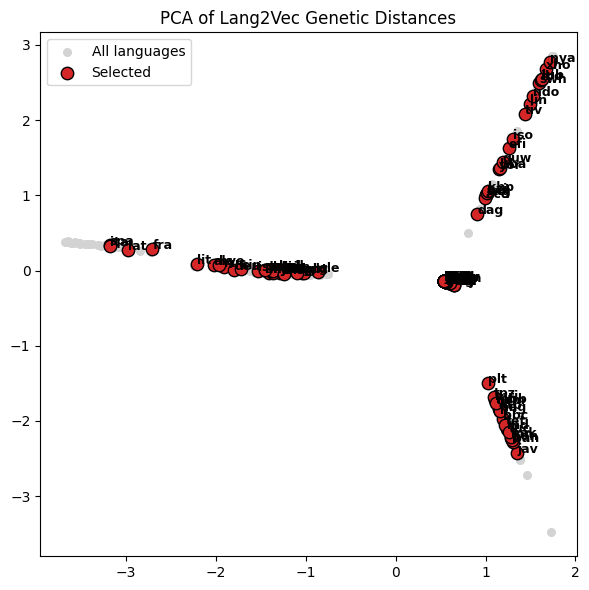

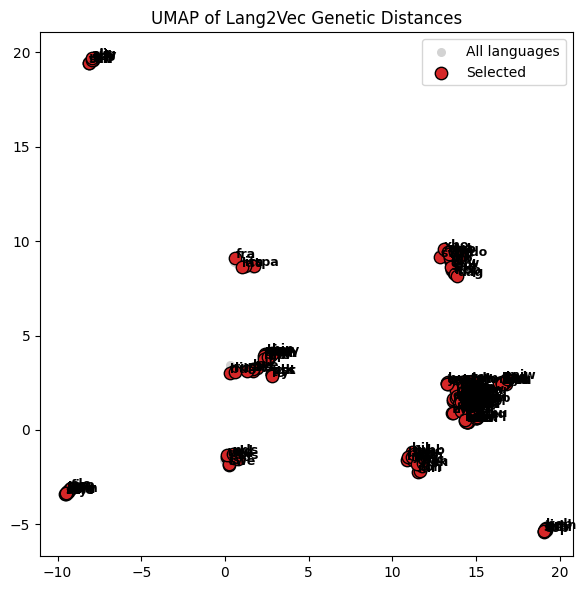

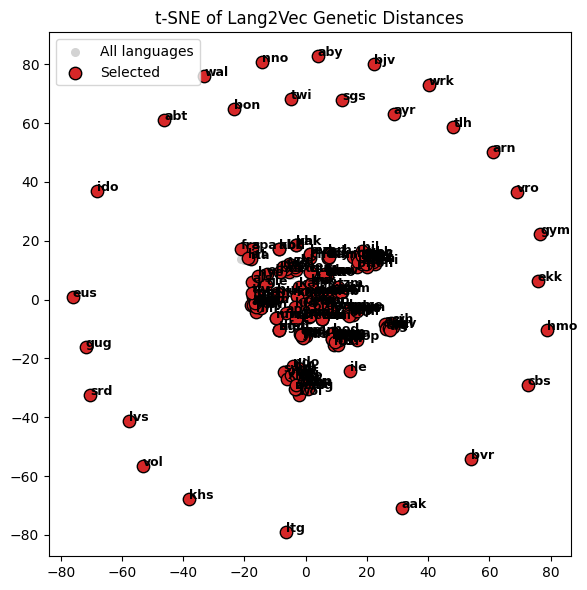

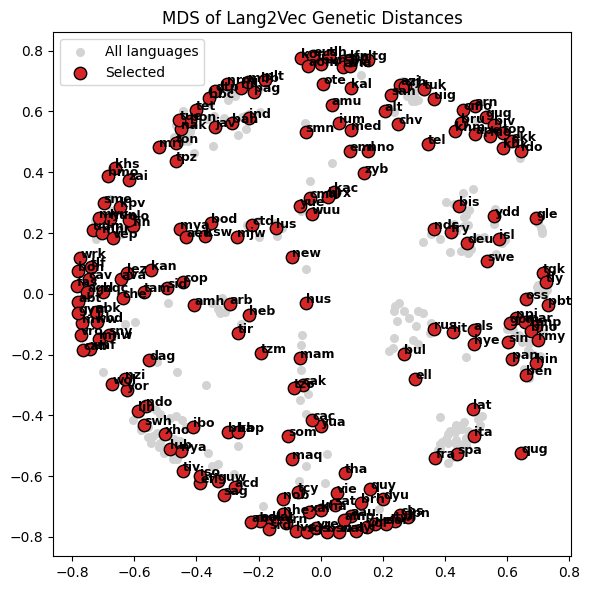

In [12]:
# Plot 2D representations
plot_pca(dist_mat, present_codes, top_n)
plot_umap(dist_mat, present_codes, top_n)
plot_tsne(dist_mat, present_codes, top_n)
plot_mds(dist_mat, present_codes, top_n)

In [13]:
# derive a list of nested sample sizes from the max value
def build_nested_sample_sizes(max_val, min_size=5, num_steps=6):
    """
    Return a list like [5, 10, 25, 50, …] that grows roughly exponentially till max_val
    """
    # Ensure the smallest size is at least 5 (or ``min_size``)
    start = max(min_size, 5)

    # Use geometric spacing to generate num_steps values including min and max
    geom = np.geomspace(start, max_val, num=num_steps) # Axel: no one cares about this distribution as long as we are showing the gradient of model's performance across the scale
    # Round, cast to int, drop duplicates, and keep only values ≤ max_clusters
    sizes = sorted({int(round(v)) for v in geom if int(round(v)) <= max_val})
    return sizes

sample_sizes = build_nested_sample_sizes(n)
print(sample_sizes)

[5, 10, 22, 46, 96, 200]


In [14]:
# Saving l2v selected languages
print('Saving l2v reprensentative sets...')
def _save_selected_in_order(selected_codes: list[str], source_df: pd.DataFrame, out_path: str):
    # Ensure the code column is a string for reliable indexing
    src = source_df.copy()
    src["code"] = src["code"].astype(str)

    # Re‑index by ``code`` and select in the desired order
    ordered = src.set_index("code").loc[selected_codes].reset_index()

    # Persist to disk
    ordered.to_csv(out_path, index=False)
    print(f"Saved ordered selection to: {out_path}")

output_dir = get_fp("data_dir/fineweb2_metadata/l2v_nested_samples/")
os.makedirs(output_dir, exist_ok=True)
for sz in sample_sizes:
    out_csv = get_fp(os.path.join(output_dir, f"{sz}.csv"))
    _save_selected_in_order(top_n[:sz], fw2_lang_doc_distr_df, out_csv)

Saving l2v reprensentative sets...
Saved ordered selection to: /cluster/user/repos/moe-study/data_dir/fineweb2_metadata/l2v_nested_samples/5.csv
Saved ordered selection to: /cluster/user/repos/moe-study/data_dir/fineweb2_metadata/l2v_nested_samples/10.csv
Saved ordered selection to: /cluster/user/repos/moe-study/data_dir/fineweb2_metadata/l2v_nested_samples/22.csv
Saved ordered selection to: /cluster/user/repos/moe-study/data_dir/fineweb2_metadata/l2v_nested_samples/46.csv
Saved ordered selection to: /cluster/user/repos/moe-study/data_dir/fineweb2_metadata/l2v_nested_samples/96.csv
Saved ordered selection to: /cluster/user/repos/moe-study/data_dir/fineweb2_metadata/l2v_nested_samples/200.csv
